## Лабораторная работа 6. Уравнение переноса методом характеристик
Постановка с фото: $u_t+v(t)u_x=0$, $v(t)=e^{-bt^2}$,
$u(x,0)=u_0(x)=e^{-ax^2}$, $0<x<\ell$, $0<t\leq T$.
Численных параметров на фото нет. Ниже выбран учебный пример.
Граничное условие слева также не задано: продолжаем гауссиану на всю
прямую. Это задаёт согласованное условие $u(0,t)=e^{-aS(t)^2}$.
Справа, где поток выходит из области, граничное условие не требуется.


In [1]:
from math import erf
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np

a, b = 25.0, 1.0
ell, T = 2.0, 2.0
N, M = 200, 200  # количество интервалов по x и t
root = Path(__file__).resolve().parent if '__file__' in globals() else Path.cwd()
out = root / 'results'

if not np.isfinite([a, b, ell, T]).all() or min(a, ell, T) <= 0 or b < 0:
    raise ValueError('Требуется a > 0, b >= 0, ell > 0, T > 0; параметры конечны.')
if not all(isinstance(k, (int, np.integer)) and k >= 2 for k in (N, M)):
    raise ValueError('N и M должны быть целыми числами не меньше 2.')
out.mkdir(parents=True, exist_ok=True)
x = np.linspace(0.0, ell, N + 1)
t = np.linspace(0.0, T, M + 1)
h, tau = ell / N, T / M


### Метод характеристик
Вдоль характеристики $dx/dt=v(t)$ и $du/dt=0$. Поэтому
$$x(t)=x_0+S(t),\qquad S(t)=\int_0^t e^{-bs^2}\,ds.$$
При $b>0$: $S(t)=\frac{\sqrt\pi}{2\sqrt b}\operatorname{erf}(\sqrt b\,t)$.
При $b=0$: $v=1$, $S(t)=t$.
Отсюда $x_0=x-S(t)$ и
$$\boxed{u(x,t)=u_0(x-S(t))=e^{-a(x-S(t))^2}.}$$
Для переменной скорости сдвиг равен интегралу скорости, а не $t v(t)$.
В области $x<S(t)$ характеристики приходят с левой границы;
выбранное продолжение начального профиля задаёт значения и в этой области.


In [2]:
def U0(x, a):
    return np.exp(-a * np.asarray(x, dtype=float) ** 2)


def v(t, b):
    return np.exp(-b * np.asarray(t, dtype=float) ** 2)


def S(t, b):
    """Интеграл скорости от 0 до t, для числа или массива; без SciPy."""
    if not np.isfinite(b) or b < 0:
        raise ValueError('b должно быть конечным и неотрицательным.')
    time = np.asarray(t, dtype=float)
    if b == 0:
        return time.copy()
    z = np.sqrt(b) * time
    values = np.fromiter((erf(float(q)) for q in z.flat), dtype=float, count=z.size)
    return np.sqrt(np.pi) / (2 * np.sqrt(b)) * values.reshape(time.shape)


shift = S(t, b)
U = np.empty((M + 1, N + 1))  # U[j, i] = u(x_i, t_j)
for j in range(M + 1):
    U[j, :] = U0(x - shift[j], a)  # все пространственные узлы i сразу


### Проверки и результаты
Проверяем начальное и выбранное граничное условия, а также невязку
исходного уравнения через независимые центральные разности с малым шагом.
Решение вычисляется по формуле, без пошаговой разностной схемы:
ограничение CFL для этого способа вычисления не требуется.


In [3]:
initial_error = np.max(np.abs(U[0] - U0(x, a)))
boundary_error = np.max(np.abs(U[:, 0] - np.exp(-a * shift ** 2)))
xp, tp = np.meshgrid(np.linspace(0.1 * ell, 0.9 * ell, 17),
                     np.linspace(0.1 * T, 0.9 * T, 17))
dx, dt = 1e-5 / np.sqrt(a), 1e-5 * min(T, 1.0 / np.sqrt(a))
ut = (U0(xp - S(tp + dt, b), a) - U0(xp - S(tp - dt, b), a)) / (2 * dt)
ux = (U0(xp + dx - S(tp, b), a) - U0(xp - dx - S(tp, b), a)) / (2 * dx)
pde_residual = np.max(np.abs(ut + v(tp, b) * ux))
assert np.isfinite(U).all() and U.min() >= 0 and U.max() <= 1
assert initial_error < 1e-12 and boundary_error < 1e-12
assert pde_residual < 1e-6 * max(1.0, np.sqrt(a)), 'Проверьте невязку уравнения.'

steps = np.unique(np.rint(np.linspace(0, M, 5)).astype(int))
np.savez_compressed(out / 'transport.npz', x=x, t=t, U=U, shift=shift,
                    velocity=v(t, b), a=a, b=b, ell=ell, T=T, N=N, M=M)
np.savetxt(out / 'profiles.csv', np.column_stack([x, U[steps].T]), delimiter=',',
           header='x,' + ','.join(f'u_t{t[j]:g}' for j in steps), comments='')
np.savetxt(out / 'motion.csv', np.column_stack([t, v(t, b), shift, U[:, 0]]),
           delimiter=',', header='t,velocity,shift,u_left', comments='')
print(f'N={N}, M={M}, h={h:g}, tau={tau:g}')
print(f'Сдвиг при t={T:g}: S(T)={shift[-1]:.8f}')
print(f'Начальное условие: {initial_error:.2e}; левая граница: {boundary_error:.2e}')
print(f'Невязка u_t + v(t)*u_x (центральные разности): {pde_residual:.2e}')
print(f'Результаты: {out}')


N=200, M=200, h=0.01, tau=0.01
Сдвиг при t=2: S(T)=0.88208139
Начальное условие: 0.00e+00; левая граница: 0.00e+00
Невязка u_t + v(t)*u_x (центральные разности): 1.78e-10
Результаты: /Users/egoriy/Desktop/mvt25/AppliedMathematics/laba6/results


### Графики решения и характеристик
На карте цвет показывает $u(x,t)$, линии — характеристики $x=x_0+S(t)$.
В каждой точке характеристики значение $u_0(x_0)$ постоянно.


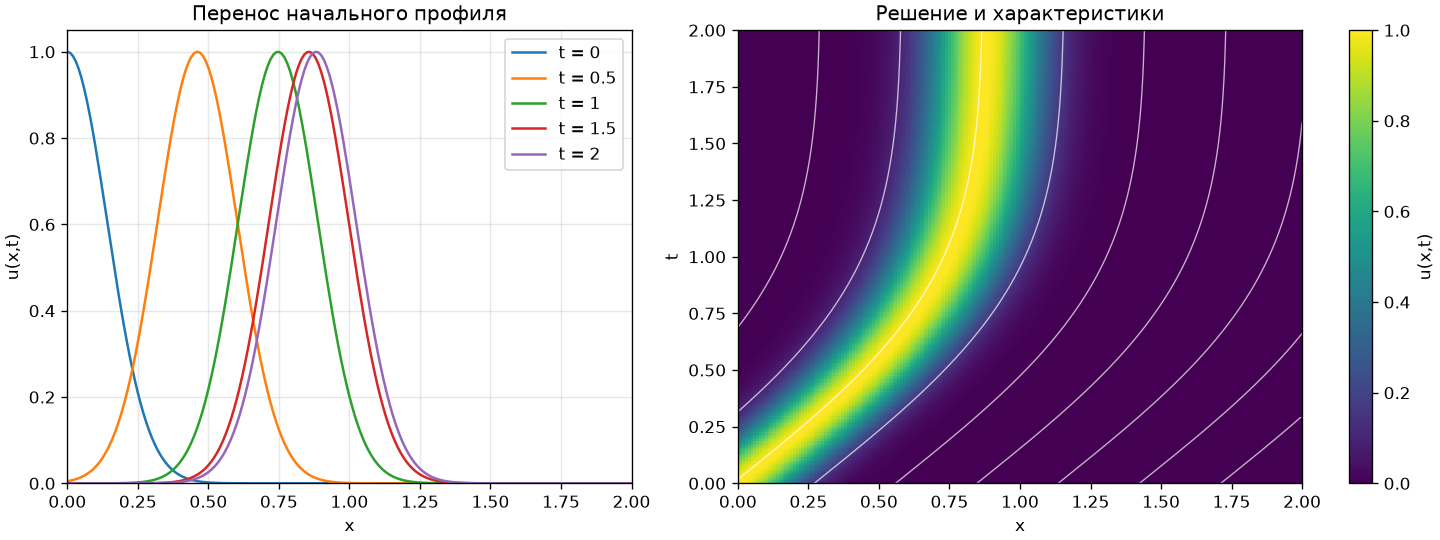

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5), constrained_layout=True)
for j in steps:
    axes[0].plot(x, U[j], label=f't = {t[j]:g}')
axes[0].set(xlabel='x', ylabel='u(x,t)', title='Перенос начального профиля',
            xlim=(0, ell), ylim=(0, 1.05))
axes[0].legend()
axes[0].grid(alpha=0.3)

image = axes[1].pcolormesh(x, t, U, shading='auto', vmin=0, vmax=1, cmap='viridis')
for x0 in np.linspace(-shift[-1], ell, 11):
    path = x0 + shift
    inside = (path >= 0) & (path <= ell)
    axes[1].plot(path[inside], t[inside], color='white', lw=0.8, alpha=0.7)
axes[1].set(xlabel='x', ylabel='t', title='Решение и характеристики',
            xlim=(0, ell), ylim=(0, T))
fig.colorbar(image, ax=axes[1], label='u(x,t)')
fig.savefig(out / 'transport.png', dpi=150)
if plt.get_backend().lower() != 'agg':
    plt.show()


### Вывод
Профиль переносится вправо, сохраняя форму вдоль характеристик.
Скорость убывает при b > 0; сдвиг стремится к sqrt(pi)/(2*sqrt(b)).
При a=25, b=1, T=2 сдвиг равен 0.88208139.
Использовано точное решение методом характеристик, вычисленное в узлах сетки.
Для другого условия u(0,t)=mu(t) решение в области x<S(t) нужно заменить
на mu(t_*), где S(t_*)=S(t)-x; начальный профиль определяет область x>=S(t).
